# E125: can the reuse definition and the decomposition both read the repeat-label pair?

**The answer.** No. The small model does hold the signal "this word already appeared in the passage" before any
training. A fine-tune learns a label from it and carries it to unseen words. But removing that signal's direction takes
away under 4 percent of the fine-tune's gain, so the frozen definition reads it "not through C", as it did the
case-label pair. Removing it at the word itself, or one layer later, takes no more. The decomposition gives the real fine-tune and a twin that only memorises the same labels, again. No
67M task yet has a reuse label to check the decomposition against.


## What we were trying to test

The one earlier pair built for the reuse definition, E112's case-label pair, failed it at the removal check. Removing
the case readout's direction barely moved the fine-tune. A suspected reason: capitalisation is written into each word's
own token, so a fine-tune can read it from many directions that one removal leaves alone. This run picks a property no
token carries, whether the word just before the marker already appeared earlier in the passage. The model has to
compute it by attention.

Each passage is a cut of Pile text with a pool word at position 19 and the marker " \+" at position 20, the trigger.
One earlier position is overwritten with the same word, so it is repeated, or with a different pool word, so it is not.
The pool is 400 words: 300 to train on, 100 held out.

- **The real arm** learns to say " carpet" after a repeated word and " camel" otherwise.
- **The twin** gets " carpet" or " camel" per word from a seeded shuffle, on the same passages. Only memory can learn
  it. It checks whether any update that teaches these labels at this trigger reads the same way.

Two seeds per arm. Each fine-tune stops at the first checkpoint where it labels 90 percent of training-word passages
right: step 30 for the real arm, step 100 for the twin.

**The definition's checks**, from `decisions.md` rows 81, 87 and 164, frozen by row 165, with E112's bars:

- *possession*: a linear readout trained on natural Pile repeats reaches 0.90 accuracy at some block before the last,
  and beats a control readout by 0.30; the control gives each word type one random value, so it scores about 0.5;
- *carrying*: the fine-tuned model labels held-out words right at least 0.90 of the time;
- *small function*: a threshold on the readout's score matches its labels on held-out words at least 0.90 of the time;
- *removal*: removing the readout's direction at the trigger takes away at least half the fine-tune's gain in label
  margin, the logit of the window's own label minus the other's. A random direction removed the same way is the floor.

**The decomposition's readings**, each with filed lines, on the log-odds of the window's own label at the trigger:

- *the route split* divides the fine-tune's gain into shares. The re-switching share $r$ is the part gained when Γ
  switches on released subcomponents it kept off before; the masked-off share is the part carried by subcomponents Γ
  still keeps off. "Re-switching" needs $r \ge 0.6$ with the masked-off share at most 0.25; "masked-off" needs that
  share at least 0.5 with $r \le 0.35$; otherwise "neither";
- *teacher training* trains the decomposition's subcomponents to copy each fine-tune, and reads the copy the same way;
- *the removal test* removes $S$, the subcomponents whose mask at the trigger rises by more than 0.3. $D(S)$ is the
  share of the gain lost in the fine-tune minus the share lost in the original model. "Through" needs at least 0.10 and
  above all 20 random sets of the same size.


## What we expected, and why

- **Possession** at about even odds. No readout of a property computed in context had been measured on this model.
- **The real arm** "reuses C", at a low lean of one in three. A fine-tune cannot read a repeat from a token's identity,
  so it might use the readout's own direction; against that, the same removal took only 0.08 on case.
- **The twin** "not through C", with an update two to three times the real's, as in E112.
- **The route split** "neither" on all four, with $r$ near 0.5 as on earlier trigger tasks. This was filed before E123
  found the case-label pair in the masked-off corner.
- **The removal test** "not" or "unclear" on both arms.


## Is the repeat signal there before the fine-tune?


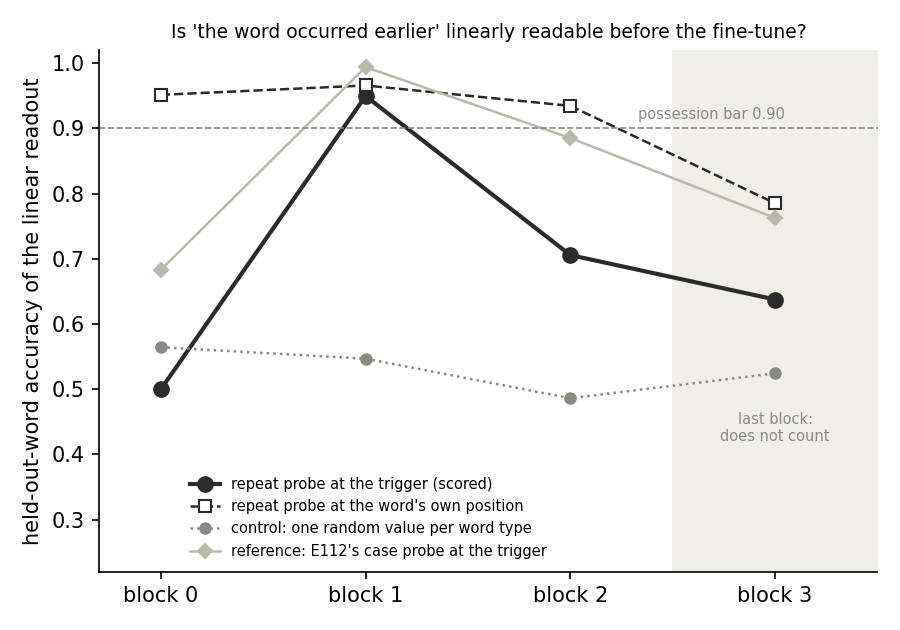

In [1]:
from IPython.display import Image

Image("../experiments/fresh_reuse_pair/figures/possession.png", width=720)


**Reading it.** Yes, at block 1, and only there at the trigger. The readout labels held-out words right 0.949 of the
time at block 1, against 0.547 for the control, so it clears both bars. At block 0 it is at chance, and by block 2 it
has fallen to 0.71. At the word's own position, one token earlier, the same readout is above 0.93 from block 0 through
block 2. So the signal is computed at the word and sits strongly at the trigger for one block. The positive control
holds: the original model predicts the token that followed the earlier occurrence 4.6 nats better in repeated passages.


## Why does the definition read "not through C"?


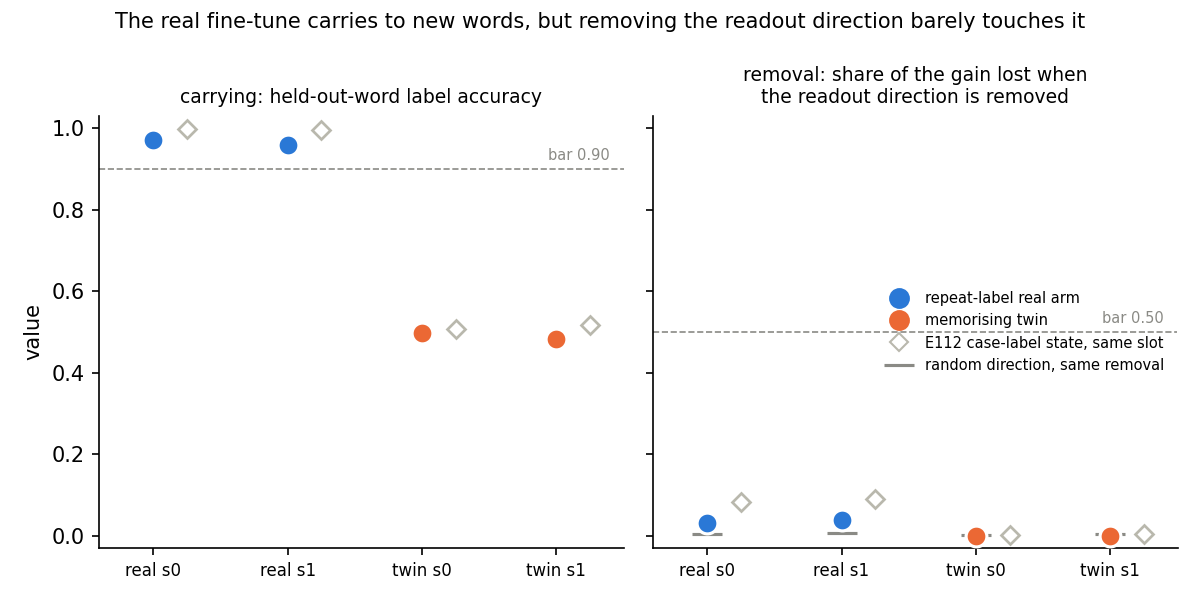

In [2]:
from IPython.display import Image

Image("../experiments/fresh_reuse_pair/figures/definition.png", width=720)


**Reading it.** Only the removal check fails, by a wide margin. The real fine-tune labels 97 and 96 percent of held-out
words right, above the 0.90 bar, and the threshold on the readout matches it about 0.93 of the time. Removing the
readout's direction takes away 0.031 and 0.038 of its gain, against a bar of 0.50. A random direction takes 0.004 and
0.007, so the direction matters, but it carries a small part of the behaviour. The case-label states, grey diamonds,
read 0.08 and 0.09: the computed property did worse, not better. A candidate reason, named in the plan:
the fine-tune may read the flag at the word's own position or at a later block, out of this removal's reach. Amendment 1,
next, tested four such sites.


## Amendment 1: does the removal work at the word's own position, or one block later?

The removal above failed at the one site the definition reads, the trigger after block 1. The reason named for it was
that the fine-tune may read the repeat flag earlier, at the repeated word's own position, where the readout already
reads 0.95 from block 0. Or it may read the flag one block later. So we removed the readout's direction at four new
sites on the same four saved fine-tunes: at the word after blocks 0, 1 and 2, and at the trigger after block 2. At each
site the readout was refit there on the same Pile rows. The quantity is the same as before: the share of the
fine-tune's label gain lost when the direction is removed, with a random direction removed the same way as the floor.
This run is descriptive: E125's verdicts stand as filed, and no number here has a bar that reads "reuses C".


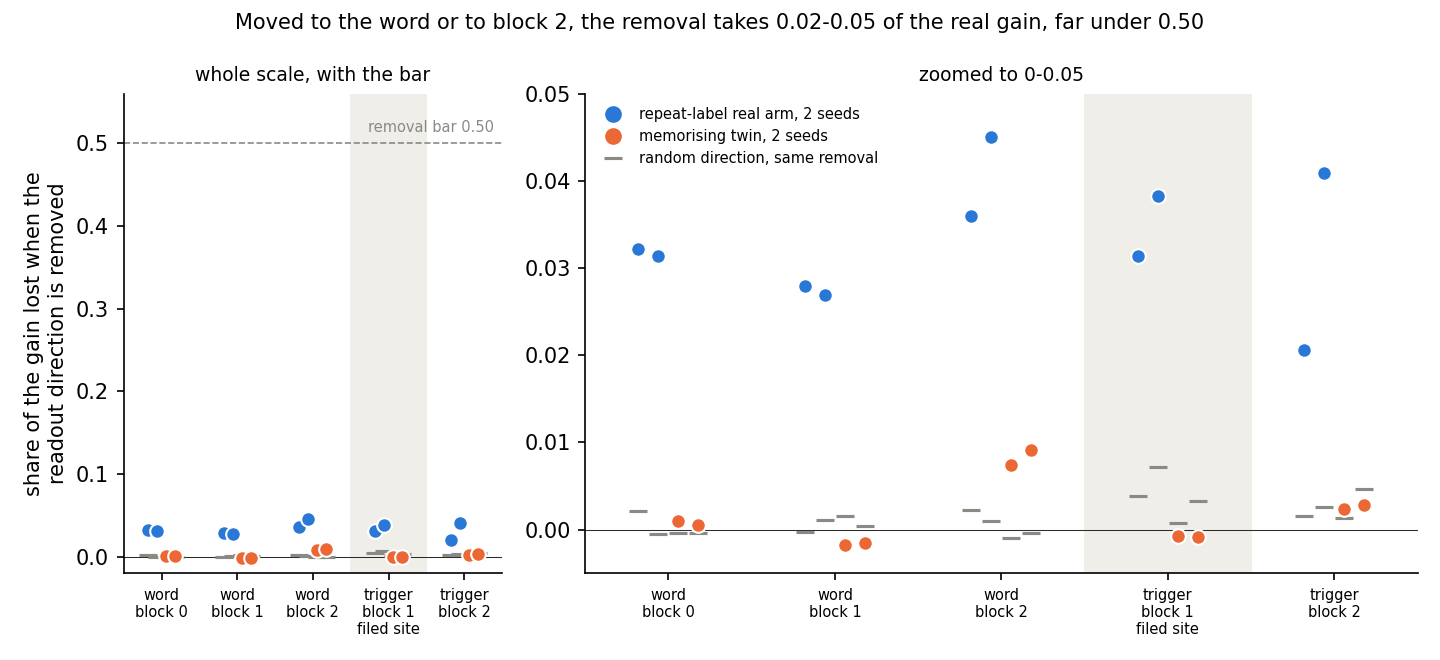

In [3]:
from IPython.display import Image

Image("../experiments/fresh_reuse_pair/figures/amend1_sites.png", width=820)


**Reading it.** Moving the removal does not rescue the clause. At every new site the real fine-tune loses 0.02 to 0.05
of its gain, the same size as at the filed site, against a bar of 0.50. No site stands out. The real arm still sits at
least ten times above its random direction at every new site, and the random readings stay within 0.005 of zero. The
twin loses almost nothing, at most 0.009, at the word after block 2. Both controls passed exactly: the refit readout
matched stage 0, and the filed share came back unchanged.

So the "wrong site" reason is ruled out for these four sites. Two readings remain, and nothing here tells them apart.
The fine-tune may use the flag a little and do most of its work another way. Or it may read the flag at many sites at
once, so that removing it at any one leaves the rest to carry it. The flat profile fits both: a single strong reading
site would show as one peak, and there is none. Only a removal at all sites together would separate them, and that
stronger form is the user's call.

The real arm is the only arm clearly above its random direction at every site, at least four times the twin. That was
already true at the filed site, and carrying had already told the arms apart. It means little for reuse: the twin's
shuffled labels carry no repeat flag, so near zero is what it is built to give, and the real arm sits an order of
magnitude under the bar. The lead read this amendment as descriptive, outside the plan's line that a stronger removal
is the user's call, since it moves the same removal and adds no rule.


## Where does each fine-tune carry its gain?


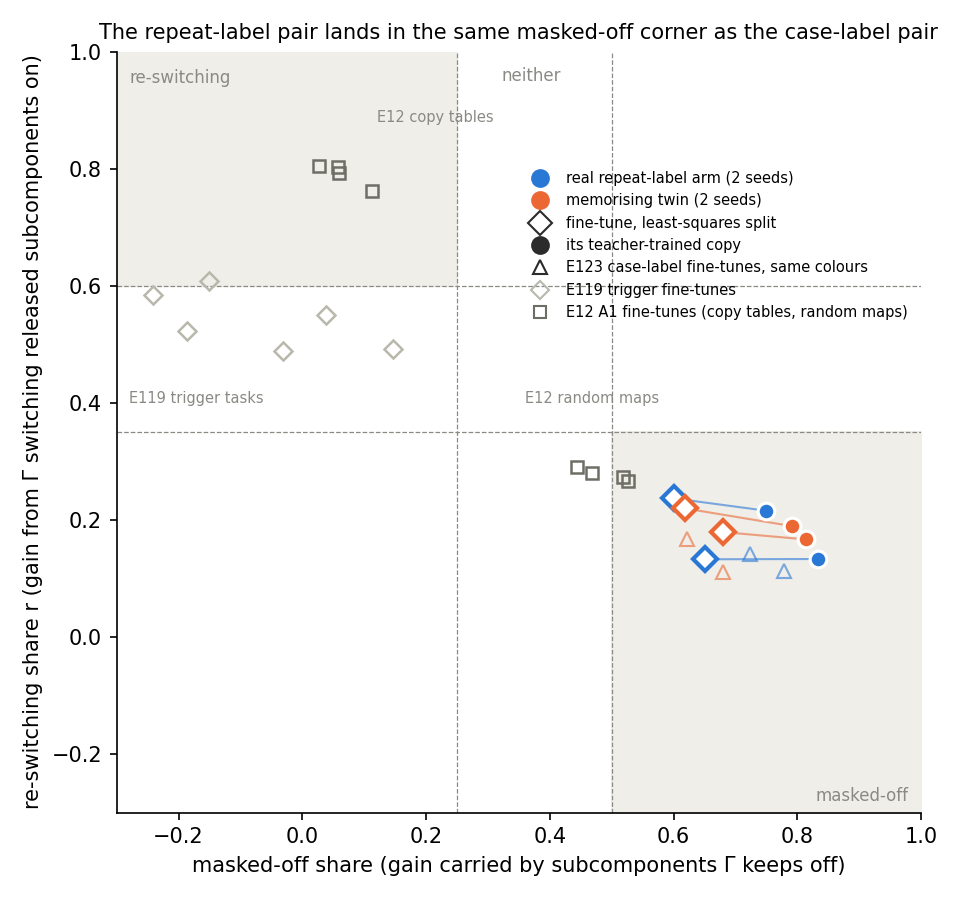

In [4]:
from IPython.display import Image

Image("../experiments/fresh_reuse_pair/figures/route.png", width=720)


**Reading it.** All four fine-tunes and all four copies sit in the masked-off corner, real and twin alike, beside the
case-label pair's triangles. Their re-switching shares are 0.13 to 0.24, and their masked-off shares 0.60 to 0.68. The
earlier trigger tasks, grey diamonds, sat near $r = 0.5$. Each copy keeps at least 0.89 of its fine-tune's gain and
moves deeper into the corner. Real and twin sit within 0.11 of each other in $r$, so this reading does not tell them
apart. The positive control held: E12's copy-table fine-tunes read re-switching and its random maps masked-off.


## Does removing the switched-on set cost the fine-tune more than chance?


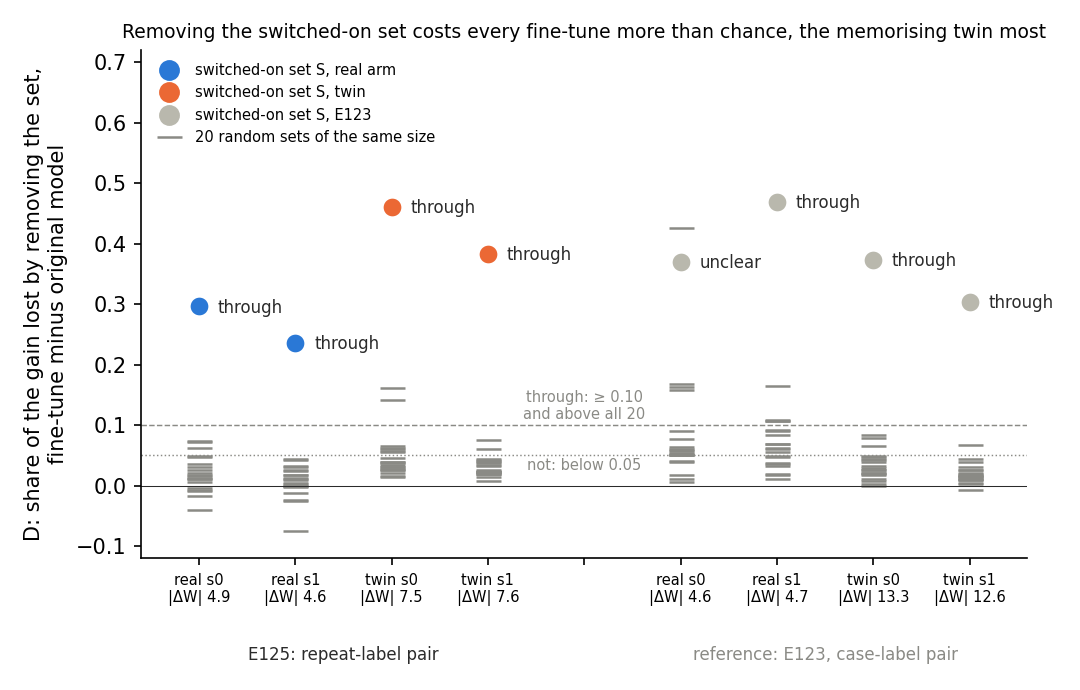

In [5]:
from IPython.display import Image

Image("../experiments/fresh_reuse_pair/figures/removal.png", width=720)


**Reading it.** Yes, on all four states, and most on the memorising twin. Removing the switched-on set costs the real
fine-tune 0.30 and 0.24 more of its gain than it costs the original model; no random set reaches 0.08. On the twin it
costs 0.46 and 0.38. All four read "through", the reuse-like label: on the real arm, where the definition says "not
through C", and on a twin built to memorise. The twin's update is about 1.6 times the real's, shown under each state,
and it is the higher pair. But across both pairs $D(S)$ does not rise with update size: E123's twins, near 13 in size, read
0.30 and 0.37, against 0.37 and 0.47 for its real states near 4.7.


## What we learned

The repeat flag was meant to give the removal check a fairer chance than case, and it failed harder: under 4 percent of
the gain against 8 to 9. So the case-label failure was not only because case lives in token identity. Nor was the site wrong: removed at the
word itself or one block later, the flag still carried only 2 to 5 percent. Two task families
now read the same way. The definition says "not through C" on every state; the route split and its copies say
masked-off on every state; the removal says "through" on seven of eight. No decomposition reading separates a real
fine-tune from its memorising twin on either pair.

The masked-off corner now holds both label pairs, which differ in the property and in whether the fine-tune reads a
feature or memorises. They share the label words, the marker, the passage layout, the recipe, and a label starting
near −14 log-odds at the trigger. So the corner looks like a property of these label tasks, but it cannot yet be told
apart from those shared parts. Whether the decomposition can see reuse is still unchecked: no 67M state reads "reuses C".


## How compelling is the evidence

- Two seeds per arm, one marker, one pair of label words; 1,600 held-out passages for carrying, 256 for the decomposition.
- Every apparatus check in stages 0 and 2 read exactly zero.
- The removal check's floor is the random direction, 0.004 and 0.007; the read sits above it and far below the bar.
- The definition's removal is rank one, at one site at a time. Amendment 1 moved it to four other sites, one by one; it
  is still blind to the flag read at several sites together.
- The route split says where Γ sends the gain, not whether the parts are new; a new circuit made of old parts reads
  "elicited" to the decomposition. The removal test misses gain spread under the 0.3 rise.


## Surprises

- **The route split's filed lean reversed in kind, as it did on E123:** filed "neither" with $r$ near 0.5, read
  masked-off with $r$ 0.13 to 0.24. Filed before E123's result, so a repeat, not new.
- **The removal test reads "through" on all four**, the twin highest; filed "not" or "unclear", real above twin.
- **The computed property failed the removal check harder than case**, against the plan's reason for hope.
- Smaller: the twin learned in 100 steps, not 300, with 1.6 times the real update, not two to three; one copy kept
  0.892 of the gain against a filed 0.90. Amendment 1's real share at the word, 0.03 to 0.05, sat inside its filed range
  but under the central guess of 0.10.


## What next

- A label pair whose label words the original model already gives some chance at the trigger. If the route split
  leaves the masked-off corner there, the corner was about the label's starting log-odds, not label tasks.
- A removal of the readout at all sites at once on the real arm. Most of the gain gone would mean the flag is read in
  many places; near 0.03 would mean the fine-tune barely uses it. It is a stronger removal form, so it is the user's call.
- A twin stopped near the real arm's update size, to read whether the removal's arm difference is size.


## Scorecard

| claim in words | rule | read | verdict |
|---|---|---|---|
| repeat readout possessed before the last block | 0.90, selectivity 0.30 | block 1: 0.949, 0.402 | held |
| real arm carries; small function | each ≥ 0.90 | 0.970, 0.960; 0.938, 0.929 | held |
| removing the readout takes half the real gain | ≥ 0.50 | 0.031, 0.038 | missed |
| real arm "reuses C" | E112's rule | not through C ×2 | missed |
| twin "not through C" | E112's rule | not through C ×2 | held |
| route split "neither", $r$ 0.45-0.65 | E119's label | masked-off ×4, $r$ 0.13-0.24 | missed |
| copies within 0.06 of the fine-tune's $r$ | E119's label | within 0.03; masked-off ×4 | $r$ held, label missed |
| removal "not" or "unclear", real above twin | E38 A2's rule | through ×4, twin higher | missed |
| A1, descriptive: real share at the word about 0.10, 0.02-0.40 | no bar | 0.027-0.045 | inside, low end |
| A1: twin share at most 0.02 in size; random at most 0.01 | no bar | −0.002 to 0.009; under 0.005 | held |
| A1 controls: refit matches stage 0; filed share returns 0.0313 | stop rules | gap 0; 0.0313 | held |

Full table, every number with its file and key: `reports/analyses/2026-11-06_analysis_e125-fresh-reuse-pair.md`.


## Not run

- A removal at several sites at once, at the earlier occurrence, or of rank above one. Amendment 1 read four single
  sites; the word after block 3 feeds nothing later, so it was skipped.
- Any of Amendment 1's sites read under the verdict; a scratch baseline beside reverse fine-tuning.
- Copies on Pile rows; the route split on held-out-word passages; a size-matched twin; other label words or markers.
- Qwen. No independent check of this write-up.

**Provenance.** MATS debug L40, $0: stage 0 job 54841, stage 1 job 54877, stage 2 job 54880, 2026-11-06, about 13
minutes in all; Amendment 1 job 54933, about 70 seconds. Results
`experiments/fresh_reuse_pair/results/stage{0,1,2}.json` and `amend1.json`; figures from
`experiments/fresh_reuse_pair/plot.py`; code at commit 9b15978c, Amendment 1 at c3a05060.
